# LAB 14: EXPECTATION-MAXIMIZATION (EM) ALGORITHM
## Gaussian Mixture Models

### Course
ICD341 - Advanced Statistical Computing

### Institution
Mulungushi University

### Student
Mwila Singoma

### Introduction
This laboratory explores the Expectation-Maximization
(EM) algorithm and Gaussian Mixture Models (GMM).

We will generate artificial datasets, perform clustering,
estimate Gaussian distribution parameters and evaluate
the model using the Bayesian Information Criterion (BIC).

### Learning Objectives
1. Understand the EM algorithm.
2. Understand Gaussian Mixture Models.
3. Generate artificial datasets using NumPy.
4. Apply GMM using Python.
5. Perform clustering.
6. Evaluate clustering models using BIC.

## Practical Exercise 1: Generating a Gaussian Dataset

### Question 1
Create a dataset containing 300 observations from three
different normally distributed groups.

The groups should have the following parameters:

- Group 1: Mean = 2, Standard deviation = 1.
- Group 2: Mean = 7, Standard deviation = 1.
- Group 3: Mean = 12, Standard deviation = 1.

Each group must contain 100 observations.

In [2]:
%pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl (8.3 MB)
Using cached narwhals-2.28.0-py3-none-any.whl (490 kB)

   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   -----------------------

In [3]:
# Import required libraries

import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture

print("All libraries imported successfully! - Lab14_EM_Gaussian_Mixture_Models.ipynb:7")

All libraries imported successfully! - Lab14_EM_Gaussian_Mixture_Models.ipynb:7


### Generating the Dataset

We will generate three normally distributed groups
using NumPy's random.normal() function.

Each group will contain 100 observations.
We will combine the groups into one dataset.

In [4]:
# Set random seed for reproducibility

np.random.seed(42)

# Generate three normally distributed groups

group1 = np.random.normal(2, 1, 100)

group2 = np.random.normal(7, 1, 100)

group3 = np.random.normal(12, 1, 100)

# Combine the three groups

data = np.concatenate([group1, group2, group3])

# Reshape the dataset for Gaussian Mixture Model

X = data.reshape(-1, 1)

# Display the total number of observations

print("Total observations:", len(X))

Total observations: 300


### Visualizing the Generated Dataset

We will use a histogram to visualize the distribution
of the 300 generated observations.

The histogram should show approximately three peaks,
representing the three underlying Gaussian groups.

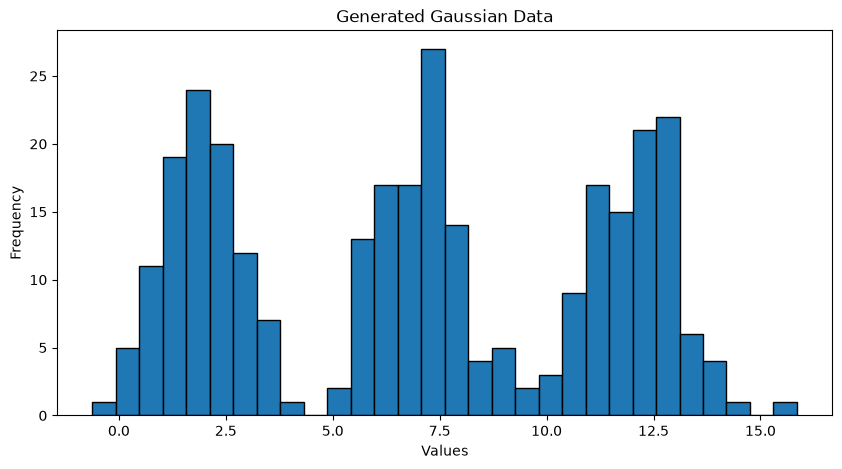

In [5]:
# Plot the generated dataset

plt.figure(figsize=(10, 5))

plt.hist(X, bins=30, edgecolor="black")

plt.title("Generated Gaussian Data")
plt.xlabel("Values")
plt.ylabel("Frequency")

plt.show()

## Practical Exercise 2: Applying the EM Algorithm

### Question 2
Use a Gaussian Mixture Model (GMM) to identify
the three underlying groups in the generated dataset.

The model will use the Expectation-Maximization (EM)
algorithm to estimate the Gaussian distributions
and assign observations to their respective groups.

In [6]:
# Create the Gaussian Mixture Model

gmm = GaussianMixture(
    n_components=3,
    random_state=42
)

print("Gaussian Mixture Model created successfully!")

Gaussian Mixture Model created successfully!


### Training the Gaussian Mixture Model

We use the fit() function to train the GMM.

During training, the Expectation-Maximization (EM)
algorithm repeatedly performs:

1. E-step: Estimates the probability that each
   observation belongs to each Gaussian component.

2. M-step: Updates the means, variances and mixing
   proportions using the estimated probabilities.

The process continues until convergence.

In [7]:
# Train the Gaussian Mixture Model

gmm.fit(X)

print("GMM training completed successfully!")

GMM training completed successfully!


c:\Users\asus\.conda\envs\icd341\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


### Predicting Group Membership

After training the model, we use predict() to assign
each observation to one of the three Gaussian components.

The predicted labels are represented by:

- 0
- 1
- 2

These numbers represent cluster identifiers,
not rankings.

In [8]:
# Predict cluster membership

labels = gmm.predict(X)

# Display the first 20 predicted labels

print("First 20 cluster labels:")
print(labels[:20])

First 20 cluster labels:
[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2]


### Visualizing the GMM Clustering Results

We use a scatter plot to display the observations
according to their predicted cluster labels.

Different colours represent different clusters.

This allows us to visually examine how successfully
the GMM has identified the three underlying groups.

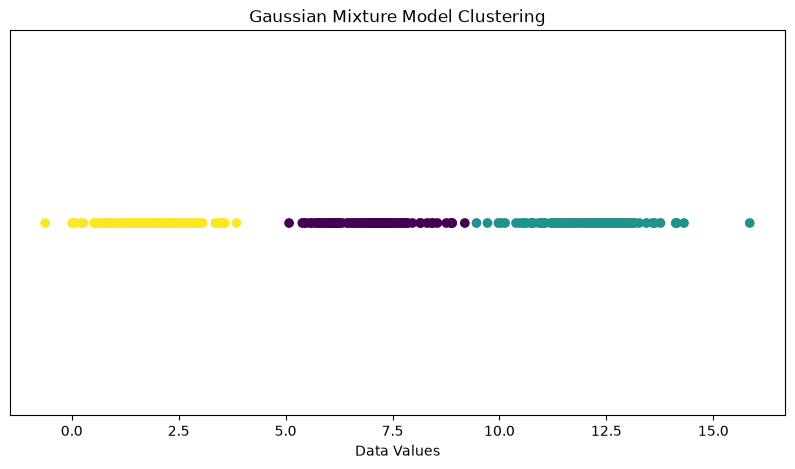

In [9]:
# Visualize GMM clustering results

plt.figure(figsize=(10, 5))

plt.scatter(
    X[:, 0],
    np.zeros(len(X)),
    c=labels,
    cmap="viridis"
)

plt.title("Gaussian Mixture Model Clustering")
plt.xlabel("Data Values")
plt.yticks([])

plt.show()

### Interpretation of Results

The Gaussian Mixture Model identifies three clusters
from the generated dataset.

Each colour represents a different Gaussian component.

The observations should form three distinct groups
around the original means of 2, 7 and 12.

This demonstrates how the Expectation-Maximization
algorithm can identify hidden group structures
within a dataset.

## Practical Exercise 3: Estimating Model Parameters

After fitting the Gaussian Mixture Model, we can examine the estimated parameters of each Gaussian component.

These parameters include:

- **Means:** The estimated centre of each Gaussian distribution.
- **Covariances:** The estimated variance or spread of each Gaussian distribution.
- **Mixing proportions:** The estimated proportion of observations belonging to each component.

We use these parameters to understand how the GMM represents the underlying data.

In [10]:
print("Estimated Means:")
print(gmm.means_)

print("\nEstimated Variances:")
print(gmm.covariances_)

print("\nMixing Proportions:")
print(gmm.weights_)

Estimated Means:
[[ 6.98734645]
 [12.04041718]
 [ 1.89614955]]

Estimated Variances:
[[[0.8221013 ]]

 [[1.19793122]]

 [[0.81819915]]]

Mixing Proportions:
[0.32957963 0.33717043 0.33324994]


### Interpretation

The Gaussian Mixture Model successfully estimated the parameters of the three underlying Gaussian distributions.

The estimated means were approximately 6.99, 12.04 and 1.90, which are close to the original means of 7, 12 and 2.

The estimated variances were also reasonably close to the original variance of 1.

The mixing proportions were approximately 0.33 for each component, indicating that the three Gaussian distributions contributed nearly equal numbers of observations.

Therefore, the EM algorithm successfully identified the underlying structure of the generated dataset.

## Practical Exercise 4: Model Selection Using BIC

The Bayesian Information Criterion (BIC) is used to compare statistical models.

It considers both how well a model fits the data and the complexity of the model.

A lower BIC value generally indicates a better model.

We will compare Gaussian Mixture Models containing 1, 2, 3 and 4 components to determine which model best represents our dataset.

In [11]:
components = [1, 2, 3, 4]
bic_values = []

for k in components:
    model = GaussianMixture(
        n_components=k,
        random_state=42
    )

    model.fit(X)

    bic = model.bic(X)
    bic_values.append(bic)

    print("Components:", k)
    print("BIC:", bic)
    print("-------------------")

Components: 1
BIC: 1733.1073308848313
-------------------
Components: 2
BIC: 1655.282818894632
-------------------
Components: 3
BIC: 1526.8347679243145
-------------------
Components: 4
BIC: 1545.735680432968
-------------------


c:\Users\asus\.conda\envs\icd341\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\asus\.conda\envs\icd341\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\asus\.conda\envs\icd341\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\asus\.conda\envs\icd341\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known

### Visualising BIC Model Selection

We can visualise the BIC values to compare the four Gaussian Mixture Models.

The model with the lowest BIC is considered the preferred model.

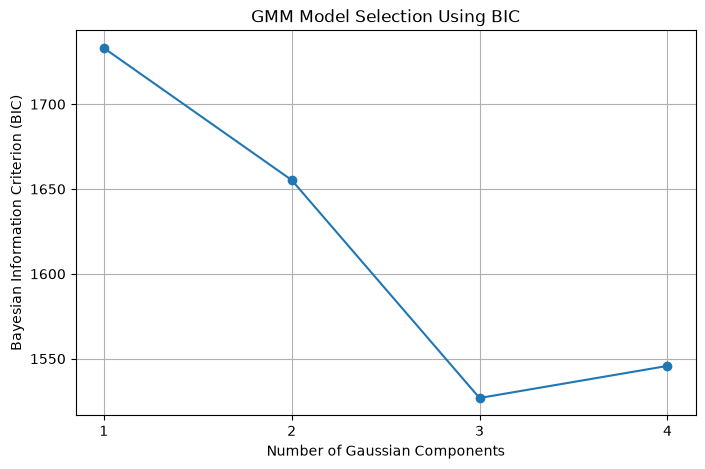

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(
    components,
    bic_values,
    marker="o",
    linestyle="-"
)

plt.xlabel("Number of Gaussian Components")
plt.ylabel("Bayesian Information Criterion (BIC)")
plt.title("GMM Model Selection Using BIC")

plt.xticks(components)
plt.grid(True)

plt.show()

### Interpretation

The BIC values decrease as the number of Gaussian components increases from 1 to 3.

The lowest BIC value is 1526.83, obtained using 3 Gaussian components.

When the number of components increases to 4, the BIC increases to 1545.74.

Therefore, the Gaussian Mixture Model with 3 components is preferred.

This agrees with the original dataset, which was generated from three Gaussian distributions with means of 2, 7 and 12.

The BIC criterion successfully identified the appropriate number of components.

## Conclusion

In this laboratory, we successfully implemented the Expectation-Maximization (EM) algorithm using Gaussian Mixture Models (GMM) in Python.

We generated a synthetic dataset containing 300 observations from three Gaussian distributions with different means. We then applied the Gaussian Mixture Model to identify the underlying clusters.

The experiment demonstrated the following:

1. **Data Generation:** We generated three groups of normally distributed observations using NumPy.
2. **Model Training:** We fitted a Gaussian Mixture Model with three components using Scikit-learn.
3. **Clustering:** The model successfully identified three clusters within the generated dataset.
4. **Parameter Estimation:** We estimated the means, variances and mixing proportions of the Gaussian components.
5. **Model Selection:** We compared models containing 1, 2, 3 and 4 components using the Bayesian Information Criterion (BIC).

The model with three components achieved the lowest BIC value of approximately 1526.83, indicating that it was the preferred model for our dataset.

Overall, this laboratory demonstrated how the EM algorithm can estimate the parameters of probabilistic models and how Gaussian Mixture Models can perform clustering without requiring predefined class labels.

## Assessment Questions and Answers

### 1. What is the Expectation-Maximization (EM) algorithm?

The Expectation-Maximization algorithm is an iterative statistical method used to estimate unknown parameters in probabilistic models, particularly when data contains hidden or missing information.

It consists of two main steps:
- **Expectation (E-step):** Estimates the probability that each observation belongs to each component.
- **Maximization (M-step):** Updates the model parameters to maximise the likelihood of the observed data.

These steps are repeated until the model converges.

### 2. What is a Gaussian Mixture Model (GMM)?

A Gaussian Mixture Model is a probabilistic model that assumes data is generated from a combination of several Gaussian distributions.

It is used for clustering and identifying underlying groups in datasets.

### 3. What is the difference between K-Means and GMM?

K-Means assigns each observation to exactly one cluster based on its distance from cluster centres.

GMM uses probability distributions to estimate the likelihood that an observation belongs to each cluster.

Therefore, GMM provides probabilistic or soft clustering, while K-Means performs hard clustering.

### 4. What is the purpose of the Bayesian Information Criterion (BIC)?

BIC is used to compare statistical models while considering both goodness of fit and model complexity.

A lower BIC value generally indicates a preferred model.

In this experiment, the model with three components achieved the lowest BIC.

### 5. Why is the EM algorithm important in statistical computing?

The EM algorithm is important because it provides a systematic approach to estimating unknown parameters in statistical models involving hidden variables.

It is applied in clustering, missing-data analysis, pattern recognition and machine learning.